In [ ]:
!pip install tensorflow pyarrow pandas scikit-learn seaborn
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


labels_path = "/content/drive/MyDrive/Classes.xlsx"
embeddings_dir = "/content/drive/MyDrive/Embedding/"

labels_df = pd.read_excel(labels_path)
labels_dict = dict(zip(labels_df["video_name"], labels_df["Class"]))

Mounted at /content/drive


In [ ]:
len(labels_dict)

704

In [ ]:
import os
import re
import pyarrow.parquet as pq
import numpy as np
from difflib import get_close_matches

def standardize_name(name):

    name = name.lower().strip()
    name = re.sub(r'[_\-\s]', '', name)
    return name

file_names = [f for f in os.listdir(embeddings_dir) if f.endswith('.parquet')]
extracted_names = [re.sub(r'your_out_path_for_df_|\.parquet', '', f) for f in file_names]

standard_labels = {standardize_name(k): (k, v) for k, v in labels_dict.items()}
standard_files = {standardize_name(name): (orig, name) for orig, name in zip(file_names, extracted_names)}

matches = []
for std_name, (orig_file, clean_name) in standard_files.items():
    if std_name in standard_labels:
        matches.append((orig_file, clean_name, standard_labels[std_name][0]))
    else:

        close_matches = get_close_matches(std_name, standard_labels.keys(), n=1, cutoff=0.85)
        if close_matches:
            matches.append((orig_file, clean_name, standard_labels[close_matches[0]][0]))

embeddings = []
targets = []

for file, extracted, matched in matches:
    file_path = os.path.join(embeddings_dir, file)
    try:
        table = pq.read_table(file_path)
        emb = table.to_pandas().values
        label = 1 if labels_dict[matched] == "Blasto" else 0
        embeddings.append(emb)
        targets.append(label)
    except Exception as e:
        print(f"  Error {file}: {e}")

if embeddings:
    max_len = max(emb.shape[0] for emb in embeddings)
    padded_embeddings = np.zeros((len(embeddings), max_len, 1536))
    for i, emb in enumerate(embeddings):
        padded_embeddings[i, :emb.shape[0], :] = emb

    X = padded_embeddings
    y = np.array(targets)

    print(f"\n Shape of data: X={X.shape}, y={y.shape}")

    with open('matched_files_report.csv', 'w') as f:
        f.write("File,Extracted Name,Matched Key\n")
        for m in matches:
            f.write(f"{m[0]},{m[1]},{m[2]}\n")
else:
    print(" No Processing !")
    X, y = None, None




 Shape of data: X=(704, 8, 1536), y=(704,)


In [ ]:
'''
import pyarrow.parquet as pq
import os

embeddings = []
targets = []

for filename in os.listdir(embeddings_dir):
    if filename.endswith(".parquet"):
        video_name = filename.replace(".parquet", "")
        if video_name in labels_dict:
            file_path = os.path.join(embeddings_dir, filename)
            table = pq.read_table(file_path)
            emb = table.to_pandas().values
            label = 1 if labels_dict[video_name] == "Blasto" else 0
            embeddings.append(emb)
            targets.append(label)

max_len = max([emb.shape[0] for emb in embeddings])
padded_embeddings = np.zeros((len(embeddings), max_len, 1536))
for i, emb in enumerate(embeddings):
    padded_embeddings[i, :emb.shape[0], :] = emb

X = padded_embeddings
y = np.array(targets)
'''

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
len(X_train)


563

In [ ]:
len(X_test)

141

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Attention, Flatten

inputs = Input(shape=(max_len, 1536))
lstm_out = LSTM(256, return_sequences=True)(inputs)
attention = Attention()([lstm_out, lstm_out])
flatten = Flatten()(attention)
outputs = Dense(1, activation='sigmoid')(flatten)

model = Model(inputs, outputs)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32
)

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.7703 - loss: 0.8987 - val_accuracy: 0.8369 - val_loss: 0.4183
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.8872 - loss: 0.3200 - val_accuracy: 0.9433 - val_loss: 0.2147
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.9273 - loss: 0.2069 - val_accuracy: 0.9433 - val_loss: 0.2063
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - accuracy: 0.9218 - loss: 0.2108 - val_accuracy: 0.9433 - val_loss: 0.2060
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.9440 - loss: 0.1778 - val_accuracy: 0.9433 - val_loss: 0.2043
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.9326 - loss: 0.1879 - val_accuracy: 0.9433 - val_loss: 0.2081
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.9340 - loss: 0.2351 - val_accuracy: 0.8369 - val_loss: 0.2591
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.8894 - loss: 0.1944 - val_accuracy: 0.

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step
              precision    recall  f1-score   support

  non-Blasto       0.92      0.87      0.90        69
      Blasto       0.94      0.97      0.96       159

    accuracy                           0.94       228
   macro avg       0.93      0.92      0.93       228
weighted avg       0.94      0.94      0.94       228



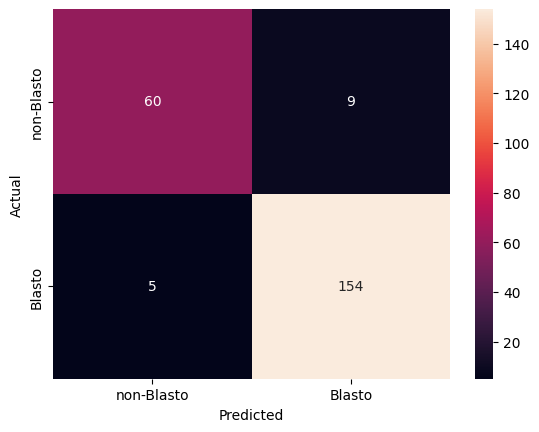

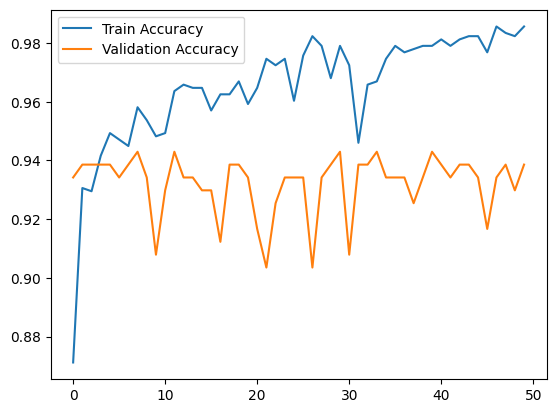

In [ ]:

y_pred = (model.predict(X_test) > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["non-Blasto", "Blasto"]))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["non-Blasto", "Blasto"], yticklabels=["non-Blasto", "Blasto"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

In [ ]:
!pip install tensorflow pyarrow pandas scikit-learn seaborn -q
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from google.colab import drive
import os
import re
import pyarrow.parquet as pq
from difflib import get_close_matches
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
import pickle
import gc

# Mount Google Drive
drive.mount('/content/drive')

# File paths
labels_path = "/content/drive/MyDrive/Classes.xlsx"
embeddings_dir = "/content/drive/MyDrive/Embedding/"
metrics_dir = "/content/drive/MyDrive/Metrics/"
data_dir = "/content/drive/MyDrive/Data/"
os.makedirs(metrics_dir, exist_ok=True)
os.makedirs(data_dir, exist_ok=True)

# Check for preprocessed data
preprocessed_data_path = os.path.join(data_dir, 'preprocessed_data.pkl')
if os.path.exists(preprocessed_data_path):
    print("Loading preprocessed data...")
    with open(preprocessed_data_path, 'rb') as f:
        data = pickle.load(f)
        X = data['X']
        y = data['y']
        max_len = data['max_len']
else:
    # Load labels
    labels_df = pd.read_excel(labels_path)
    labels_dict = dict(zip(labels_df["video_name"], labels_df["Class"]))

    def standardize_name(name):
        name = name.lower().strip()
        name = re.sub(r'[_\-\s]', '', name)
        return name

    # Load and match files
    file_names = [f for f in os.listdir(embeddings_dir) if f.endswith('.parquet')]
    extracted_names = [re.sub(r'your_out_path_for_df_|\.parquet', '', f) for f in file_names]

    standard_labels = {standardize_name(k): (k, v) for k, v in labels_dict.items()}
    standard_files = {standardize_name(name): (orig, name) for orig, name in zip(file_names, extracted_names)}

    matches = []
    for std_name, (orig_file, clean_name) in standard_files.items():
        if std_name in standard_labels:
            matches.append((orig_file, clean_name, standard_labels[std_name][0]))
        else:
            close_matches = get_close_matches(std_name, standard_labels.keys(), n=1, cutoff=0.85)
            if close_matches:
                matches.append((orig_file, clean_name, standard_labels[close_matches[0]][0]))

    # Load embeddings and targets
    embeddings = []
    targets = []
    for file, extracted, matched in matches:
        file_path = os.path.join(embeddings_dir, file)
        try:
            table = pq.read_table(file_path)
            emb = table.to_pandas().values
            label = 1 if labels_dict[matched] == "Blasto" else 0
            embeddings.append(emb)
            targets.append(label)
        except Exception as e:
            print(f"Error processing {file}: {e}")

    if embeddings:
        max_len = max(emb.shape[0] for emb in embeddings)
        padded_embeddings = np.zeros((len(embeddings), max_len, 1536))
        for i, emb in enumerate(embeddings):
            padded_embeddings[i, :emb.shape[0], :] = emb

        X = padded_embeddings
        y = np.array(targets)

        print(f"\nShape of data: X={X.shape}, y={y.shape}")

        with open(os.path.join(data_dir, 'matched_files_report.csv'), 'w') as f:
            f.write("File,Extracted Name,Matched Key\n")
            for m in matches:
                f.write(f"{m[0]},{m[1]},{m[2]}\n")
    else:
        print("No valid files were processed!")
        X, y = None, None

    # Save preprocessed data
    if X is not None and y is not None:
        with open(preprocessed_data_path, 'wb') as f:
            pickle.dump({'X': X, 'y': y, 'max_len': max_len}, f)

# Gradient accumulation
class GradientAccumulation:
    def __init__(self, model, accumulation_steps):
        self.model = model
        self.accumulation_steps = accumulation_steps
        self.optimizer = model.optimizer
        self.loss_fn = tf.keras.losses.BinaryCrossentropy()
        self.accumulated_gradients = [tf.zeros_like(var) for var in model.trainable_variables]

    def train_step(self, x, y):
        with tf.GradientTape() as tape:
            predictions = self.model(x, training=True)
            loss = self.loss_fn(y, predictions)
        gradients = tape.gradient(loss, self.model.trainable_variables)
        self.accumulated_gradients = [acc + grad / self.accumulation_steps for acc, grad in zip(self.accumulated_gradients, gradients)]
        return loss

    def apply_gradients(self):
        self.optimizer.apply_gradients(zip(self.accumulated_gradients, self.model.trainable_variables))
        self.accumulated_gradients = [tf.zeros_like(var) for var in self.model.trainable_variables]

# Store metrics for each run
all_metrics = defaultdict(list)
n_runs = 10

for run in range(n_runs):
    print(f"\nRun {run + 1}/{n_runs}")

    # Set random seed
    tf.random.set_seed(42 + run)
    np.random.seed(42 + run)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 + run, stratify=y)

    # Compute class weights
    class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    class_weights_dict = dict(enumerate(class_weights))

    # Build model
    inputs = Input(shape=(max_len, 1536))
    lstm_out = layers.LSTM(256, return_sequences=True)(inputs)
    attention = layers.Attention()([lstm_out, lstm_out])
    flatten = layers.Flatten()(attention)
    outputs = layers.Dense(1, activation='sigmoid')(flatten)
    model = models.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Training with gradient accumulation
    accumulation_steps = 2
    ga = GradientAccumulation(model, accumulation_steps)
    batch_size = 16
    steps_per_epoch = len(X_train) // batch_size
    epochs = 50

    history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

    for epoch in range(epochs):
        print(f"Epoch {epoch + 1}/{epochs}")
        epoch_loss = 0
        for step in range(steps_per_epoch):
            idx = np.random.choice(len(X_train), batch_size, replace=False)
            x_batch, y_batch = X_train[idx], y_train[idx]
            loss = ga.train_step(x_batch, y_batch)
            epoch_loss += loss
            if (step + 1) % accumulation_steps == 0:
                ga.apply_gradients()
        epoch_loss /= steps_per_epoch
        history['loss'].append(float(epoch_loss))

        # Validation
        val_pred = model.predict(X_test, verbose=0)
        val_loss = model.compiled_loss(y_test, val_pred)
        val_metrics = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
        history['val_loss'].append(float(val_loss))
        history['accuracy'].append(val_metrics['accuracy'])
        history['val_accuracy'].append(val_metrics['val_accuracy'])

    # Evaluate model
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int)
    report = classification_report(y_test, y_pred, target_names=["non-Blasto", "Blasto"], output_dict=True)

    # Store metrics for both classes
    metrics = {
        'accuracy': history['val_accuracy'][-1],
        'precision_non_blasto': report['non-Blasto']['precision'],
        'recall_non_blasto': report['non-Blasto']['recall'],
        'f1_non_blasto': report['non-Blasto']['f1-score'],
        'precision_blasto': report['Blasto']['precision'],
        'recall_blasto': report['Blasto']['recall'],
        'f1_blasto': report['Blasto']['f1-score'],
        'X_test': X_test,
        'y_test': y_test,
        'history': history
    }

    # Save metrics
    with open(os.path.join(metrics_dir, f'metrics_run_{run + 1}.pkl'), 'wb') as f:
        pickle.dump(metrics, f)

    # Clear memory
    tf.keras.backend.clear_session()
    gc.collect()

    # Save model and data for the last run
    if run == n_runs - 1:
        model.save(os.path.join(metrics_dir, 'lstm_model_last_run.h5'))
        with open(os.path.join(metrics_dir, 'last_run_data.pkl'), 'wb') as f:
            pickle.dump({'X_test': X_test, 'y_test': y_test, 'history': history}, f)

# Calculate mean and std
metrics_summary = {
    metric: {
        'mean': np.mean(values),
        'std': np.std(values)
    } for metric, values in all_metrics.items()
}

# Print summary
print("\nMetrics Summary (Mean ± STD):")
for metric, stats in metrics_summary.items():
    print(f"{metric}: {stats['mean']:.4f} ± {stats['std']:.4f}")

# Final evaluation with plots
def evaluate_model(model, X_test, y_test, history, run_metrics):
    # Set seaborn style for better aesthetics
    sns.set_style("whitegrid", {'grid.linestyle': '--', 'grid.alpha': 0.7})

    y_pred = (model.predict(X_test) > 0.5).astype(int)

    print("\nFinal Classification Report (Last Run):")
    print(classification_report(y_test, y_pred, target_names=["non-Blasto", "Blasto"]))

    # Confusion Matrix
    plt.figure(figsize=(8, 6), dpi=100)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["non-Blasto", "Blasto"],
                yticklabels=["non-Blasto", "Blasto"])
    plt.title("Confusion Matrix (Last Run)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # Training History
    plt.figure(figsize=(12, 5), dpi=100)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Validation Accuracy')
    plt.title("Training History - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

# Load last run's model and data for final evaluation
model_path = os.path.join(metrics_dir, 'lstm_model_last_run.h5')
data_path = os.path.join(metrics_dir, 'last_run_data.pkl')

if os.path.exists(model_path) and os.path.exists(data_path):
    model = tf.keras.models.load_model(model_path)
    with open(data_path, 'rb') as f:
        last_run_data = pickle.load(f)
        X_test = last_run_data['X_test']
        y_test = last_run_data['y_test']
        history = last_run_data['history']
    evaluate_model(model, X_test, y_test, history, metrics_summary)
else:
    print("Model or data files not found. Ensure all 10 runs are completed.")